<a href="https://colab.research.google.com/github/santoshjoshi368/CM1_Common/blob/main/Intro_tensorflow_cel_farh.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This is a project that is being practiced using the codes from udemy. The name of the course in Udemy is **Intro to Tensorflow for Deep Learning**. So most of the code might be the copyright for the udemy. I have used those codes only for the purpose of learning and nothing else.

In [3]:
import tensorflow as tf
import numpy as np
import logging
logger = tf.get_logger()
logger.setLevel(logging.ERROR)

We have import Tensorflow and numpy and these will be libriaries we will be using currently. We are trying to create a conventional python function that directly performs the calculation of  f = c x 1.8 +32.

Creating a python function is a easier way of doing this. But this method will not be machine learning. Hence, we will give tensorflow some sample celcius values (0,8,15,22,28) and their corrosponding fahrenheit values (32,46,59, 72, 100). Then we will train a model that figures out the above formula through training process.

Set Up training data:

In [5]:
celsius_q = np.array([-40,-10,0,8,15,22,38],dtype = float)
fahrenheit_a = np.array([-40,14,32,46,59,72,100],dtype = float)

for i,c in enumerate(celsius_q):
  print("{} degrees Celsius = {} degrees Fahrenheit".format(c,fahrenheit_a[i]))

-40.0 degrees Celsius = -40.0 degrees Fahrenheit
-10.0 degrees Celsius = 14.0 degrees Fahrenheit
0.0 degrees Celsius = 32.0 degrees Fahrenheit
8.0 degrees Celsius = 46.0 degrees Fahrenheit
15.0 degrees Celsius = 59.0 degrees Fahrenheit
22.0 degrees Celsius = 72.0 degrees Fahrenheit
38.0 degrees Celsius = 100.0 degrees Fahrenheit


**Create a Model:**

We can use dense network to create a simplest model as of now. This network will require only a single layer, with a single neuron.

In [12]:
l0 = tf.keras.layers.Dense(units = 10, input_shape = [1])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


tf.keras.layers.Dense is used to instantiate the layer.

Similarly, input_shape =[1] -- This specifies that the input in the input layer is a single value. That is, the shape is a one - dimensional array with one member.

Units =1 , This specifies the number of neurons in the layer. The number of neurons defines how many internal variables the layer has to try to learn how to solve the problem.

In [7]:
model = tf.keras.Sequential([l0])

Before training the model, the model needs to be compiled. When compiled for training, the model is given:

**Loss function** - a way of measuring how far off predictions are from the  desired outcome.

**Optimizer function** -- a way of adjusting internal values in order to reduce the loss.

In [13]:
model.compile(loss = 'mean_squared_error', optimizer =tf.keras.optimizers.Adam(0.1))

These are used during training to first calculate the loss at each point, and then improve it.

During training, the optimizer function is used to calculate adjustments to the model's vaiables. The goal is to adjust the internal variables until the model mirrors the equation for converting celcius to fahrenheit.

Tensorflow used numerical analysis to perform this tuning.

The loss function and the optimizer (Adam) used here are standard for simple models. The learning rate here 0.1 is the step size taken when adjusting values in the models. If the value is too small, it will take too many interations train the model and if the vlaue is very large, the accurancy of the model goes down.

In [14]:
history = model.fit(celsius_q, fahrenheit_a, epochs=500, verbose= False)
print("finished training the model")

finished training the model


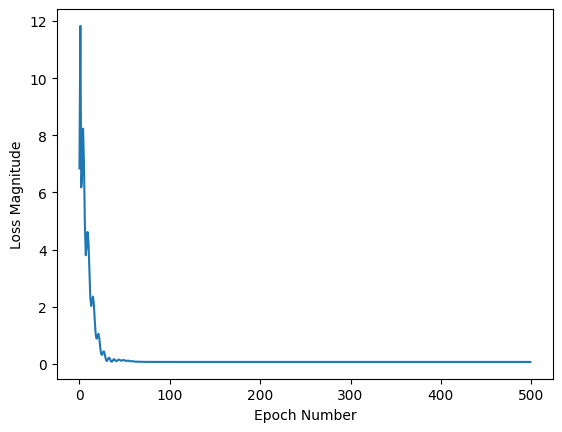

In [15]:
import matplotlib.pyplot as plt
plt.xlabel('Epoch Number')
plt.ylabel("Loss Magnitude")
plt.plot(history.history['loss'])

In [25]:
model.predict(np.array([[100]]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


array([[211.74745]], dtype=float32)

In [29]:
print("These are the layer variables: {}".format(model.get_weights()))

These are the layer variables: [array([[1.7979492]], dtype=float32), array([31.952524], dtype=float32)]


In [30]:
l0 = tf.keras.layers.Dense(units=4, input_shape=[1])
l1 = tf.keras.layers.Dense(units=4)
l2 = tf.keras.layers.Dense(units=1)
model = tf.keras.Sequential([l0, l1, l2])
model.compile(loss='mean_squared_error', optimizer=tf.keras.optimizers.Adam(0.1))
model.fit(celsius_q, fahrenheit_a, epochs=500, verbose=False)
print("Finished training the model")
print(model.predict([100.0]))
print("Model predicts that 100 degrees Celsius is: {} degrees Fahrenheit".format(model.predict([100.0])))
print("These are the l0 variables: {}".format(l0.get_weights()))
print("These are the l1 variables: {}".format(l1.get_weights()))
print("These are the l2 variables: {}".format(l2.get_weights()))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Finished training the model


ValueError: Unrecognized data type: x=[100.0] (of type <class 'list'>)